# Assignment 49 — Week 2, Day 4
## Topic: Statistics — Mean, Median and Mode

**Objective:** Calculate mean, median, and mode.

**Reference:** https://www.w3schools.com/python/python_ml_mean_median_mode.asp

In machine learning (and in mathematics) there are often three values that interest us:

- **Mean** – the average value
- **Median** – the mid point value
- **Mode** – the most common value

Example: the speed of 13 cars has been registered:

`speed = [99, 86, 87, 88, 111, 86, 103, 87, 94, 78, 77, 85, 86]`

**Diagram:** How each of the three values is worked out for the speed data.

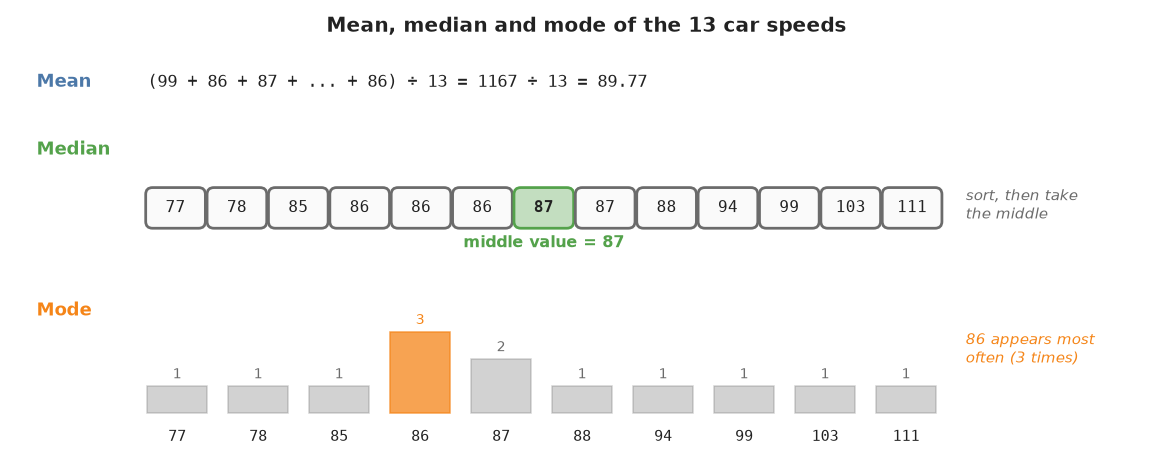

**Mean: calculate it by hand**

In [1]:
speed = [99, 86, 87, 88, 111, 86, 103, 87, 94, 78, 77, 85, 86]

total = sum(speed)
count = len(speed)

print("Sum:", total)
print("Count:", count)
print("Mean:", total / count)

Sum: 1167
Count: 13
Mean: 89.76923076923077


**Explanation:** The mean is the average: add up all the values and divide by how many there are. 1167 ÷ 13 = 89.77.

**Mean with NumPy**

In [2]:
import numpy

speed = [99, 86, 87, 88, 111, 86, 103, 87, 94, 78, 77, 85, 86]

x = numpy.mean(speed)

print(x)

89.76923076923077


**Explanation:** NumPy's mean() method gives the same result in one line.

**Median with NumPy**

In [3]:
import numpy

speed = [99, 86, 87, 88, 111, 86, 103, 87, 94, 78, 77, 85, 86]

print(sorted(speed))

x = numpy.median(speed)

print(x)

[77, 78, 85, 86, 86, 86, 87, 87, 88, 94, 99, 103, 111]
87.0


**Explanation:** The median is the value in the middle after sorting all the values. With 13 values, the 7th value (87) is in the middle.

**Diagram:** When there is no single middle value, the median is the average of the two middle values.

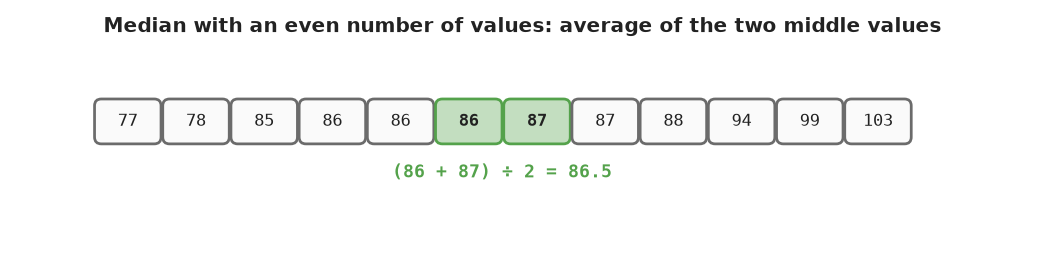

**Median of an even number of values**

In [4]:
import numpy

speed = [99, 86, 87, 88, 86, 103, 87, 94, 78, 77, 85, 86]

print(sorted(speed))

x = numpy.median(speed)

print(x)

[77, 78, 85, 86, 86, 86, 87, 87, 88, 94, 99, 103]
86.5


**Explanation:** With 12 values there are two middle numbers, 86 and 87. The median is their average, 86.5.

**Mode with SciPy**

In [5]:
from scipy import stats

speed = [99, 86, 87, 88, 111, 86, 103, 87, 94, 78, 77, 85, 86]

x = stats.mode(speed)

print(x)
print("Mode:", x.mode, "| appears", x.count, "times")

ModeResult(mode=np.int64(86), count=np.int64(3))
Mode: 86 | appears 3 times


**Explanation:** The mode is the value that appears most often. NumPy has no mode function, so SciPy's stats.mode() is used. It returns the mode (86) and how many times it appears (3).

**Mean, median and mode with Python's statistics module**

In [6]:
import statistics

speed = [99, 86, 87, 88, 111, 86, 103, 87, 94, 78, 77, 85, 86]

print("Mean:", round(statistics.mean(speed), 2))
print("Median:", statistics.median(speed))
print("Mode:", statistics.mode(speed))
print("All modes:", statistics.multimode([1, 1, 2, 2, 3]))

Mean: 89.77
Median: 87
Mode: 86
All modes: [1, 2]


**Explanation:** Python's built-in statistics module calculates all three without NumPy or SciPy. multimode() returns every value that ties for most common.

**How an outlier affects the mean and the median**

In [7]:
import numpy

speed = [99, 86, 87, 88, 111, 86, 103, 87, 94, 78, 77, 85, 86]
with_outlier = speed + [300]

print("Mean:  ", round(numpy.mean(speed), 2), "->", round(numpy.mean(with_outlier), 2))
print("Median:", numpy.median(speed), "->", numpy.median(with_outlier))

Mean:   89.77 -> 104.79
Median: 87.0 -> 87.0


**Explanation:** Adding one extreme value (300) pulls the mean up by about 15, but the median barely moves. The median is a better summary when the data has outliers.

**Show the three values on a chart**

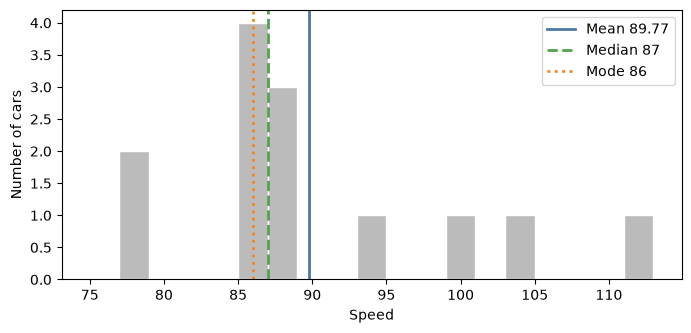

In [8]:
import numpy
import matplotlib.pyplot as plt
from scipy import stats

speed = [99, 86, 87, 88, 111, 86, 103, 87, 94, 78, 77, 85, 86]

plt.figure(figsize=(8, 3.5))
plt.hist(speed, bins=range(75, 115, 2), color="#BBBBBB", edgecolor="white")
plt.axvline(numpy.mean(speed), color="#4C78A8", linewidth=2, label=f"Mean {numpy.mean(speed):.2f}")
plt.axvline(numpy.median(speed), color="#54A24B", linewidth=2, linestyle="--", label=f"Median {numpy.median(speed):.0f}")
plt.axvline(stats.mode(speed).mode, color="#F58518", linewidth=2, linestyle=":", label=f"Mode {stats.mode(speed).mode}")
plt.xlabel("Speed")
plt.ylabel("Number of cars")
plt.legend()
plt.show()

**Explanation:** The histogram shows that most speeds are in the 80s. The mean is higher than the median and mode because a few fast cars (103, 111) pull it up.

## Observation

- The mean is the sum of the values divided by the count (89.77 for the speeds).
- The median is the middle value after sorting (87); with an even count it is the average of the two middle values.
- The mode is the most common value (86, which appears 3 times).
- NumPy provides mean() and median(), SciPy provides stats.mode(), and Python's statistics module provides all three.
- Outliers pull the mean much more than the median.

## Conclusion

Mean, median and mode each describe the "centre" of a data set in a different way. Comparing them shows whether the data is balanced or pulled by extreme values, which is useful before building machine learning models.